# 27. KAIST three-sensor translation information: LiDAR–LiDAR residuals and observability

**Question:** Do 5-second KAIST windows contain recoverable *signed* translation-calibration information when we compare the two LiDAR odometries explicitly? This notebook has **no NN training** and does **not** use a learned checkpoint.

The two independent scan-to-map pose streams are converted to relative motions on **the same physical time intervals**, each expressed in the same body frame. For a fixed extrinsic rotation, the body-frame translation of a LiDAR relative pose obeys

\[
\Delta p_B=R_{BL}\Delta p_L+(I-\Delta R_B)t_{BL},\qquad \Delta R_B=R_{BL}\Delta R_L R_{BL}^T.
\]

The pairwise residual and its analytic translation Jacobians are

\[
r_i=p_{B,i}^{\mathrm{left}}-p_{B,i}^{\mathrm{right}},\qquad
J_{i,L}=I-\Delta R_{B,i}^{L},\quad J_{i,R}=-(I-\Delta R_{B,i}^{R}).
\]

**Scientific safeguards:**
- We use the **current candidate calibration**, not hidden ground truth, to calculate residuals and Jacobians. The nominal `T_B_L` values are treated as a *reference* solely to label artificially injected translation errors.
- A one-sensor conditional least-squares test is an **oracle diagnostic**: it assumes we know which of the two LiDAR extrinsics was perturbed. It is **not** a deployable fault isolator.
- A baseline-subtracted residual is shown only as an **oracle signal upper bound**, never as an inference-time input.
- `J.T @ J` is a **motion-consistency information proxy**, not your marginalized factor-graph calibration Fisher matrix. A joint left/right estimate has weak common-origin gauge directions.
- A 5-second window may show near-zero sensitivity even when a multi-minute aggregation is informative.

## 1. Imports and repository root

In [1]:
from pathlib import Path
from dataclasses import dataclass
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.spatial.transform import Rotation, Slerp

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Could not locate the nn-obs-calib repository root.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
from obscalib.config import WindowingConfig

print('Repository:', ROOT)
print('NumPy:', np.__version__)
print('This notebook does not instantiate or train a neural network.')

Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
NumPy: 1.26.4
This notebook does not instantiate or train a neural network.


## 2. Paths, reference calibration, and evaluation settings

In [2]:
KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
LIDAR_POSE_ROOT = Path('/home/camel/Skoltech/phd_proposal/data/KAISTDataset')
TRAIN_NAMES = ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
VAL_NAMES = ['Urban26', 'Urban28']
TEST_NAMES = ['Urban38', 'Urban39']
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES
CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700

# Evaluation uses uniformly spaced physical windows per sequence, never a partial *training* dataset.
WINDOWS_PER_SEQUENCE = 15
PLOT_SEQUENCE = 'Urban38'
PLOT_WINDOWS = 8
TRANSLATION_SWEEP_CM = np.linspace(-50.0, 50.0, 81)
INJECTED_MAGNITUDES_CM = (5.0, 10.0, 20.0, 50.0)
MIN_MATCHED_INTERVALS = 8
TIME_MARGIN_S = 0.001

# A synthetic injected change alters exactly one LiDAR translation in body coordinates.
# Reference values are used only as a synthetic labeling convention; their physical accuracy is not assumed.
T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457, 1.90953],
    [ 0.0, 0.0, 0.0, 1.0],
], dtype=np.float64)
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642,  0.712109,  1.91294],
    [ 0.0, 0.0, 0.0, 1.0],
], dtype=np.float64)
T_I_B = np.array([
    [1., 0., 0., -0.07],
    [0., 1., 0., 0.],
    [0., 0., 1., 1.7],
    [0., 0., 0., 1.],
], dtype=np.float64)
rig_calibration = KAISTRigCalibration(
    T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L,
    T_B_L_right=T_B_L_right, tau_imu_s=0.0,
    tau_lidar_s=0.0, tau_lidar_right_s=0.0,
)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
print('Selected evaluation scale:', WINDOWS_PER_SEQUENCE, 'windows per sequence')

Selected evaluation scale: 15 windows per sequence


## 3. Reconstruct relative LiDAR pose trajectories with correct interval semantics

The KAIST loader provides `inverse(T_W_L_previous) @ T_W_L_current` per interval and separate interval-start/interval-end timestamps. We reconstruct a local trajectory up to an irrelevant left-multiplicative global frame, then interpolate *poses* (linear position + SO(3) SLERP) to query both sensors at exactly the same times. Interpolating each relative twist independently would not be equivalent.

In [3]:
def _numpy(tensor):
    return tensor.detach().cpu().numpy().astype(np.float64, copy=False)


def _as_transform(tensor):
    result = _numpy(tensor)
    if result.shape == (1, 4, 4):
        result = result[0]
    if result.shape != (4, 4):
        raise ValueError(f'Expected an SE3 transform, got {result.shape}')
    return result


def _as_scalar(tensor):
    value = _numpy(tensor).reshape(-1)
    if len(value) != 1:
        raise ValueError(f'Expected scalar tau, got {value.shape}')
    return float(value[0])


def invert_se3(T):
    T = np.asarray(T, dtype=np.float64)
    result = np.broadcast_to(np.eye(4, dtype=np.float64), T.shape).copy()
    Rt = np.swapaxes(T[..., :3, :3], -1, -2)
    result[..., :3, :3] = Rt
    result[..., :3, 3] = -(Rt @ T[..., :3, 3, None])[..., 0]
    return result


@dataclass
class PoseInterpolator:
    times: np.ndarray
    translations: np.ndarray
    rotations: Slerp

    @classmethod
    def from_relative_stream(cls, stream, tau_s):
        if stream.interval_start_timestamps is None:
            raise ValueError('LiDAR stream must contain interval_start_timestamps.')
        t0 = _numpy(stream.interval_start_timestamps).reshape(-1) + tau_s
        t1 = _numpy(stream.timestamps).reshape(-1) + tau_s
        delta_T = _numpy(stream.values)
        if delta_T.ndim != 3 or delta_T.shape[1:] != (4, 4):
            raise ValueError(f'Expected unbatched [N,4,4] LiDAR relative transforms, got {delta_T.shape}')
        if len(t0) < MIN_MATCHED_INTERVALS or np.any(t1 <= t0) or np.any(np.diff(t1) <= 0):
            return None
        # Do not silently integrate across an absent odometry interval.
        if np.any(np.abs(t0[1:] - t1[:-1]) > 0.002):
            return None
        times = np.concatenate(([t0[0]], t1))
        if np.any(np.diff(times) <= 0):
            return None
        poses = np.repeat(np.eye(4)[None], len(times), axis=0)
        for i in range(len(delta_T)):
            poses[i + 1] = poses[i] @ delta_T[i]
        rotations = Slerp(times, Rotation.from_matrix(poses[:, :3, :3]))
        return cls(times=times, translations=poses[:, :3, 3], rotations=rotations)

    def at(self, times):
        times = np.asarray(times, dtype=np.float64).reshape(-1)
        if len(times) and (times.min() < self.times[0] - 1e-8 or times.max() > self.times[-1] + 1e-8):
            raise ValueError('Pose interpolation requested outside the source coverage.')
        result = np.repeat(np.eye(4)[None], len(times), axis=0)
        result[:, :3, :3] = self.rotations(times).as_matrix()
        for axis in range(3):
            result[:, axis, 3] = np.interp(times, self.times, self.translations[:, axis])
        return result

    def relative(self, start_times, end_times):
        start_poses, end_poses = self.at(start_times), self.at(end_times)
        return invert_se3(start_poses) @ end_poses

## 4. Match the **same** intervals in both LiDARs; derive residual and Jacobian

A per-window `MotionPair` caches aligned relative motions. The left-LiDAR timestamps define the interval grid; the right LiDAR is interpolated to the same interval boundaries. The valid interval set is selected once, independent of candidate extrinsic translation.

In [4]:
@dataclass
class MotionPair:
    sequence: str
    index: int
    T_left: np.ndarray
    T_right: np.ndarray
    delta_left: np.ndarray
    delta_right: np.ndarray
    starts: np.ndarray
    ends: np.ndarray


def prepare_motion_pair(window, sequence='unknown', index=-1):
    left, right = window.streams['lidar'], window.streams['lidar_right']
    cal_left, cal_right = window.current_calibration['lidar'], window.current_calibration['lidar_right']
    tau_left, tau_right = _as_scalar(cal_left.time_offset), _as_scalar(cal_right.time_offset)
    left_trajectory = PoseInterpolator.from_relative_stream(left, tau_left)
    right_trajectory = PoseInterpolator.from_relative_stream(right, tau_right)
    if left_trajectory is None or right_trajectory is None:
        return None
    starts = _numpy(left.interval_start_timestamps).reshape(-1) + tau_left
    ends = _numpy(left.timestamps).reshape(-1) + tau_left
    valid = (starts >= right_trajectory.times[0] + TIME_MARGIN_S) & (ends <= right_trajectory.times[-1] - TIME_MARGIN_S)
    valid &= (ends > starts)
    if int(valid.sum()) < MIN_MATCHED_INTERVALS:
        return None
    starts, ends = starts[valid], ends[valid]
    return MotionPair(
        sequence=sequence, index=index,
        T_left=_as_transform(cal_left.transform), T_right=_as_transform(cal_right.transform),
        delta_left=left_trajectory.relative(starts, ends),
        delta_right=right_trajectory.relative(starts, ends),
        starts=starts, ends=ends,
    )


def body_translation_and_jacobian(relative_poses, T_B_L):
    """Body-frame relative translation and dp_B/dt_BL, with extrinsic rotation fixed."""
    R = T_B_L[:3, :3]
    t = T_B_L[:3, 3]
    delta_R_B = R[None] @ relative_poses[:, :3, :3] @ R.T[None]
    J = np.eye(3)[None] - delta_R_B
    p_B = (R[None] @ relative_poses[:, :3, 3, None])[..., 0] + (J @ t[None, :, None])[..., 0]
    return p_B, J


def translation_pair_data(pair, delta_left=None, delta_right=None):
    """Residual r_left_minus_right, J_left and J_right, all in the body frame."""
    Tl, Tr = pair.T_left.copy(), pair.T_right.copy()
    if delta_left is not None:
        Tl[:3, 3] += np.asarray(delta_left, dtype=np.float64)
    if delta_right is not None:
        Tr[:3, 3] += np.asarray(delta_right, dtype=np.float64)
    p_left, J_left = body_translation_and_jacobian(pair.delta_left, Tl)
    p_right, J_right_pos = body_translation_and_jacobian(pair.delta_right, Tr)
    return p_left - p_right, J_left, -J_right_pos


def residual_rms_m(residual):
    return float(np.sqrt(np.mean(np.sum(np.asarray(residual, dtype=float) ** 2, axis=-1))))


def jacobian_diagnostics(J):
    J_flat = J.reshape(-1, 3)
    H = J_flat.T @ J_flat
    eigvals = np.linalg.eigvalsh(H)
    singular_values = np.linalg.svd(J_flat, compute_uv=False)
    ratio = float(eigvals[0] / eigvals[-1]) if eigvals[-1] > 1e-14 else 0.0
    return H, eigvals, singular_values, ratio


def translation_ls_update(residual, J, relative_damping=0.01, max_update_m=0.50):
    """One conditional correction, assuming the perturbed LiDAR is known."""
    J_flat = J.reshape(-1, 3)
    H = J_flat.T @ J_flat
    g = J_flat.T @ residual.reshape(-1)
    damping = relative_damping * max(float(np.linalg.eigvalsh(H)[-1]), 1e-10) + 1e-9
    update = -np.linalg.solve(H + damping * np.eye(3), g)
    unclipped_norm = float(np.linalg.norm(update))
    if unclipped_norm > max_update_m:
        update *= max_update_m / unclipped_norm
    return update, dict(H=H, g=g, damping=damping, raw_norm_m=unclipped_norm)

## 5. Synthetic geometric checks (no dataset required)

These checks verify frame conversion, the minus sign on the right-LiDAR Jacobian, the finite-difference derivative, and that applying a known 20 cm left-LiDAR translation perturbation changes the residual by `J @ delta`.

In [5]:
from types import SimpleNamespace

rng_check = np.random.default_rng(2027)
T_body = np.eye(4)
T_body[:3, :3] = Rotation.from_rotvec([0.04, -0.12, 0.19]).as_matrix()
T_body[:3, 3] = [0.6, -0.2, 0.1]
T_left_test, T_right_test = T_B_L.copy(), T_B_L_right.copy()
delta_L = invert_se3(T_left_test) @ T_body @ T_left_test
delta_R = invert_se3(T_right_test) @ T_body @ T_right_test
fake = SimpleNamespace(T_left=T_left_test, T_right=T_right_test, delta_left=np.repeat(delta_L[None], 12, axis=0), delta_right=np.repeat(delta_R[None], 12, axis=0))
r_zero, JL, JR = translation_pair_data(fake)
assert residual_rms_m(r_zero) < 1e-5, residual_rms_m(r_zero)
for key, J in [('lidar', JL), ('lidar_right', JR)]:
    for axis in range(3):
        v = np.zeros(3)
        v[axis] = 1e-5
        plus = translation_pair_data(fake, delta_left=v if key == 'lidar' else None, delta_right=v if key == 'lidar_right' else None)[0]
        minus = translation_pair_data(fake, delta_left=-v if key == 'lidar' else None, delta_right=-v if key == 'lidar_right' else None)[0]
        numerical = (plus - minus) / (2 * v[axis])
        np.testing.assert_allclose(numerical, J[:, :, axis], atol=1e-9, rtol=1e-7)
delta = np.array([0.12, -0.06, 0.15])
r_pert, _, _ = translation_pair_data(fake, delta_left=delta)
np.testing.assert_allclose(r_pert - r_zero, (JL @ delta[:, None])[..., 0], atol=1e-9)
print('Synthetic SE3 and both LiDAR translation Jacobians: PASS')

Synthetic SE3 and both LiDAR translation Jacobians: PASS


## 6. Load KAIST three-sensor windows

All original train, validation, and test sequences are loaded with exactly the dataset and rig conventions used in notebooks 25/26. The analysis below selects a reproducible sample of windows per sequence; no model is trained on a restricted dataset.

In [6]:
all_specs = build_kaist_sequence_specs(
    sequence_names=ALL_SEQUENCE_NAMES,
    kaist_dataset_root=KAIST_DATASET_ROOT,
    lidar_pose_root=LIDAR_POSE_ROOT,
    lidar_right_pose_filename='lidar_map_poses_vlp_right.csv',
)
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f'Missing right LiDAR for {spec.name}: {spec.lidar_right_pose_csv}')
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[k] for k in TRAIN_NAMES], rig_calibration, windowing_config)
val_dataset = KAISTCalibrationDataset([spec_by_name[k] for k in VAL_NAMES], rig_calibration, windowing_config)
test_dataset = KAISTCalibrationDataset([spec_by_name[k] for k in TEST_NAMES], rig_calibration, windowing_config)
SPLIT_DATASETS = {'train': train_dataset, 'validation': val_dataset, 'test': test_dataset}
SEQUENCE_DATASETS = {name: dataset for _, dataset in SPLIT_DATASETS.items() for name in dataset.sequence_names}
for split_name, dataset in SPLIT_DATASETS.items():
    assert tuple(dataset.calibration_keys) == CALIBRATION_KEYS
    print(f'{split_name}: {len(dataset)} windows / {dataset.sequence_names}')

train: 2006 windows / ('Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16')
validation: 418 windows / ('Urban26', 'Urban28')
test: 699 windows / ('Urban38', 'Urban39')


## 7. Collect aligned physical windows and check coverage

This check is important: missing LiDAR poses, scan gaps and non-overlapping timestamps are not silently bridged by interpolation.

In [7]:
def select_motion_pairs(sequence_name, max_windows=WINDOWS_PER_SEQUENCE):
    dataset = SEQUENCE_DATASETS[sequence_name]
    indices = np.asarray(list(dataset.window_indices_for_sequence(sequence_name)), dtype=int)
    if max_windows is not None and len(indices) > max_windows:
        indices = np.unique(np.linspace(0, len(indices) - 1, max_windows, dtype=int))
    pairs, rejected = [], 0
    for idx in indices:
        pair = prepare_motion_pair(dataset[int(idx)], sequence=sequence_name, index=int(idx))
        if pair is None:
            rejected += 1
        else:
            pairs.append(pair)
    return pairs, rejected

MOTION_PAIRS = {}
for sequence_name in ALL_SEQUENCE_NAMES:
    pairs, rejected = select_motion_pairs(sequence_name)
    MOTION_PAIRS[sequence_name] = pairs
    print(f'{sequence_name:9s}: usable={len(pairs):3d}, rejected={rejected:3d}, matched intervals={sum(len(p.starts) for p in pairs):5d}')

if sum(len(p) for p in MOTION_PAIRS.values()) == 0:
    raise RuntimeError('No overlapping LiDAR windows found. Check timestamp conventions and interval continuity.')

Urban08  : usable= 15, rejected=  0, matched intervals=  715
Urban12  : usable= 15, rejected=  0, matched intervals=  708
Urban13  : usable= 15, rejected=  0, matched intervals=  707
Urban14  : usable= 15, rejected=  0, matched intervals=  705
Urban15  : usable= 15, rejected=  0, matched intervals=  707
Urban16  : usable= 15, rejected=  0, matched intervals=  687
Urban26  : usable= 15, rejected=  0, matched intervals=  713
Urban28  : usable= 15, rejected=  0, matched intervals=  708
Urban38  : usable= 15, rejected=  0, matched intervals=  700
Urban39  : usable= 15, rejected=  0, matched intervals=  714


## 8. Translation residual sweeps: X/Y/Z, each LiDAR

A single isolated LiDAR translation is swept while the other LiDAR extrinsic stays at its nominal reference. Show both the **raw** residual and the **oracle baseline-subtracted** residual. The oracle curve reveals the geometry-only signature of the injected displacement but is *not* an admissible model input.

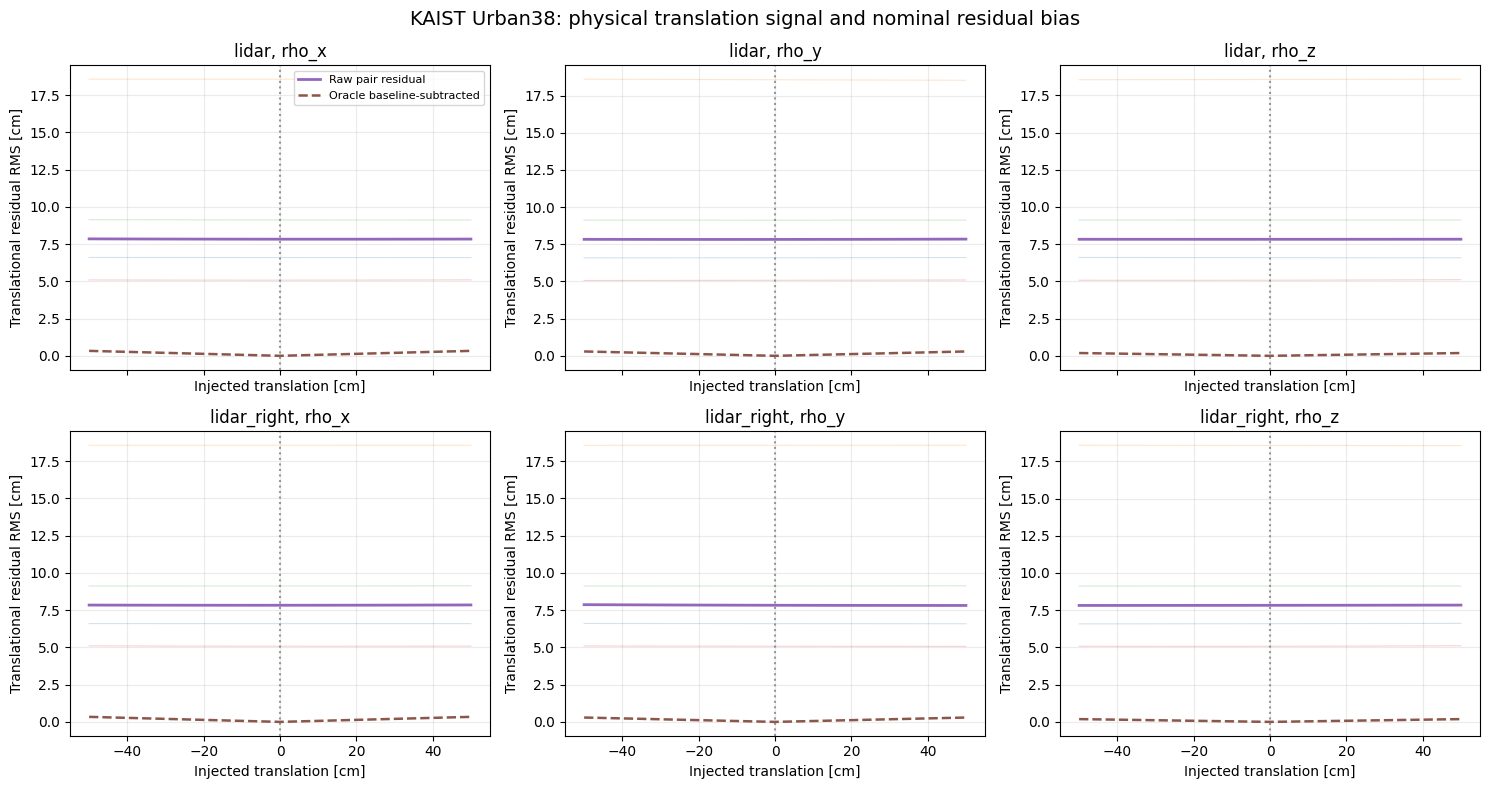

In [8]:
def translation_sweep(pair, sensor_key, axis, sweep_m):
    reference, JL, JR = translation_pair_data(pair)
    J = JL if sensor_key == 'lidar' else JR
    direction = np.eye(3)[axis]
    # Analytic dependence is exact for fixed extrinsic rotation.
    response = (J @ direction[:, None])[..., 0]
    raw = np.array([residual_rms_m(reference + a * response) for a in sweep_m])
    oracle = np.array([residual_rms_m(a * response) for a in sweep_m])
    return raw, oracle


plot_pairs = MOTION_PAIRS[PLOT_SEQUENCE][:PLOT_WINDOWS]
if not plot_pairs:
    raise ValueError(f'No usable pairs in {PLOT_SEQUENCE}')
sweep_m = TRANSLATION_SWEEP_CM * 0.01
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for row, key in enumerate(('lidar', 'lidar_right')):
    for axis in range(3):
        ax = axes[row, axis]
        raw_curves, oracle_curves = [], []
        for pair in plot_pairs:
            raw, oracle = translation_sweep(pair, key, axis, sweep_m)
            raw_curves.append(raw * 100.0)
            oracle_curves.append(oracle * 100.0)
        raw_mean = np.mean(raw_curves, axis=0)
        oracle_mean = np.mean(oracle_curves, axis=0)
        for values in raw_curves[:4]:
            ax.plot(TRANSLATION_SWEEP_CM, values, alpha=0.20, linewidth=0.8)
        ax.plot(TRANSLATION_SWEEP_CM, raw_mean, linewidth=2.0, label='Raw pair residual')
        ax.plot(TRANSLATION_SWEEP_CM, oracle_mean, '--', linewidth=1.8, label='Oracle baseline-subtracted')
        ax.axvline(0, color='grey', linestyle=':', alpha=0.8)
        ax.set_title(f'{key}, rho_{"xyz"[axis]}')
        ax.set_xlabel('Injected translation [cm]')
        ax.set_ylabel('Translational residual RMS [cm]')
        ax.grid(alpha=0.25)
        if row == 0 and axis == 0:
            ax.legend(fontsize=8)
fig.suptitle(f'KAIST {PLOT_SEQUENCE}: physical translation signal and nominal residual bias', fontsize=14)
fig.tight_layout()
plt.show()

## 9. Jacobian spectrum and joint left/right gauge

`J.T @ J` contains sensitivity to translation under the *fixed* LiDAR–LiDAR motion comparisons. It does not account for unknown trajectory, motion-estimation correlations, gyro errors, or other factor-graph nuisance states. Compare 3D conditional Jacobians with the joint 6D problem.

          baseline_rms_cm  left_ratio  right_ratio  joint_sigma_ratio
sequence                                                             
Urban08          7.034941    0.213806     0.137744           0.109313
Urban12         13.986996    0.277301     0.305831           0.196593
Urban13         16.327669    0.430080     0.413227           0.247498
Urban14         23.308637    0.344470     0.351162           0.173078
Urban15         10.167315    0.340056     0.345070           0.198414
Urban16         11.341388    0.352589     0.273541           0.253924
Urban26         11.075960    0.400092     0.368274           0.299383
Urban28         11.685843    0.372380     0.397065           0.232809
Urban38          7.464853    0.360200     0.220293           0.224582
Urban39          6.157884    0.340405     0.220293           0.209093


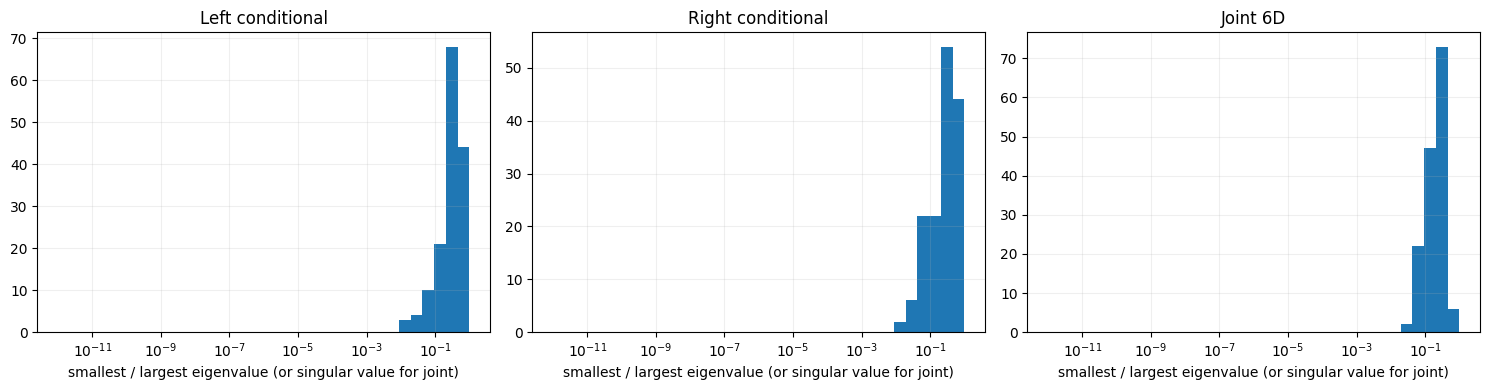

Example joint [left rho, right rho] singular values: [0.0330832  0.02859514 0.02138902 0.01127476 0.00990473 0.00770005]
Weakest 6D translation direction: [-0.6718 -0.3509  0.0848 -0.5582 -0.3169  0.079 ]


In [9]:
spectral_records = []
for sequence_name, pairs in MOTION_PAIRS.items():
    for pair in pairs:
        r0, JL, JR = translation_pair_data(pair)
        left_H, left_e, _, left_ratio = jacobian_diagnostics(JL)
        right_H, right_e, _, right_ratio = jacobian_diagnostics(JR)
        J6 = np.concatenate((JL, JR), axis=2).reshape(-1, 6)
        s6 = np.linalg.svd(J6, compute_uv=False)
        spectral_records.append(dict(
            sequence=sequence_name, window_index=pair.index,
            intervals=len(pair.starts), baseline_rms_cm=100 * residual_rms_m(r0),
            left_lambda_min=left_e[0], left_lambda_max=left_e[-1], left_ratio=left_ratio,
            right_lambda_min=right_e[0], right_lambda_max=right_e[-1], right_ratio=right_ratio,
            joint_sigma_min=s6[-1], joint_sigma_max=s6[0],
            joint_sigma_ratio=s6[-1] / max(s6[0], 1e-12),
        ))
spectrum = pd.DataFrame(spectral_records)
print(spectrum.groupby('sequence')[['baseline_rms_cm', 'left_ratio', 'right_ratio', 'joint_sigma_ratio']].median().round(6).to_string())
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, field, name in zip(axes, ('left_ratio', 'right_ratio', 'joint_sigma_ratio'), ('Left conditional', 'Right conditional', 'Joint 6D')):
    values = spectrum[field].to_numpy()
    ax.hist(np.clip(values, 1e-12, 1.0), bins=np.logspace(-12, 0, 36))
    ax.set_xscale('log')
    ax.set_xlabel('smallest / largest eigenvalue (or singular value for joint)')
    ax.set_title(name)
    ax.grid(alpha=0.2)
fig.tight_layout(); plt.show()

pair_example = plot_pairs[0]
r0, JL, JR = translation_pair_data(pair_example)
J6 = np.concatenate((JL, JR), axis=2).reshape(-1, 6)
_, s6, Vh = np.linalg.svd(J6, full_matrices=False)
print('Example joint [left rho, right rho] singular values:', np.round(s6, 9))
print('Weakest 6D translation direction:', np.round(Vh[-1], 4))

## 10. One-sensor translation: direct LS correction versus zero predictor

For each selected window, inject a known translation into either the left or right LiDAR while keeping the other *nominally fixed*. A conditional regularized least-squares estimate uses the raw residual and its Jacobian, as would be possible if the faulty sensor were known. For comparison, an oracle variant subtracts the residual at the reference calibration and is therefore **not deployable**. Label accuracy is relative to the nominal calibration, which may itself contain systematic bias.

In [10]:
def score_injected_translation(pair, sensor_key, delta):
    kwargs = {'delta_left': delta} if sensor_key == 'lidar' else {'delta_right': delta}
    r_prior, JL, JR = translation_pair_data(pair, **kwargs)
    J = JL if sensor_key == 'lidar' else JR
    correction_raw, details = translation_ls_update(r_prior, J)
    r_reference, _, _ = translation_pair_data(pair)
    correction_oracle, _ = translation_ls_update(r_prior - r_reference, J)
    # true synthetic correction in the selected sensor's *body translation coordinates*: -delta
    initial_error = float(np.linalg.norm(delta))
    after_raw = float(np.linalg.norm(delta + correction_raw))
    after_oracle = float(np.linalg.norm(delta + correction_oracle))
    return dict(
        initial_cm=100 * initial_error,
        after_raw_cm=100 * after_raw, after_oracle_cm=100 * after_oracle,
        nominal_false_update_cm=100 * np.linalg.norm(translation_ls_update(r_reference, J)[0]),
        residual_prior_cm=100 * residual_rms_m(r_prior),
        residual_reference_cm=100 * residual_rms_m(r_reference),
        update_gain_raw=-float(np.dot(correction_raw, delta)) / max(float(np.dot(delta, delta)), 1e-12),
        update_gain_oracle=-float(np.dot(correction_oracle, delta)) / max(float(np.dot(delta, delta)), 1e-12),
        capped=bool(details['raw_norm_m'] > 0.50),
    )


def evaluate_split_translation(split_name, seed=2701):
    sequence_names = {'train': TRAIN_NAMES, 'validation': VAL_NAMES, 'test': TEST_NAMES}[split_name]
    rng = np.random.default_rng(seed)
    rows = []
    for sequence_name in sequence_names:
        for pair in MOTION_PAIRS[sequence_name]:
            for key in ('lidar', 'lidar_right'):
                for magnitude_cm in INJECTED_MAGNITUDES_CM:
                    direction = rng.standard_normal(3)
                    direction /= np.linalg.norm(direction)
                    delta = direction * (0.01 * magnitude_cm)
                    result = score_injected_translation(pair, key, delta)
                    rows.append(dict(split=split_name, sequence=sequence_name, window_index=pair.index, sensor=key, magnitude_cm=magnitude_cm, **result))
    return pd.DataFrame(rows)

results = pd.concat([evaluate_split_translation(k) for k in SPLIT_DATASETS], ignore_index=True)
summary = results.groupby(['split', 'sensor', 'magnitude_cm'])[['initial_cm', 'after_raw_cm', 'after_oracle_cm', 'nominal_false_update_cm', 'update_gain_raw']].median().round(2)
print(summary.to_string())

                                     initial_cm  after_raw_cm  after_oracle_cm  nominal_false_update_cm  update_gain_raw
split      sensor      magnitude_cm                                                                                     
test       lidar       5.0                  5.0         50.65             0.08                     50.0            -0.82
                       10.0                10.0         53.57             0.18                     50.0            -1.35
                       20.0                20.0         50.00             0.31                     50.0             0.50
                       50.0                50.0         66.24             0.97                     50.0             0.12
           lidar_right 5.0                  5.0         49.92             0.08                     50.0             0.67
                       10.0                10.0         49.46             0.22                     50.0             0.77
                       20.0     

## 11. Plot before/after recovery and inspect false corrections

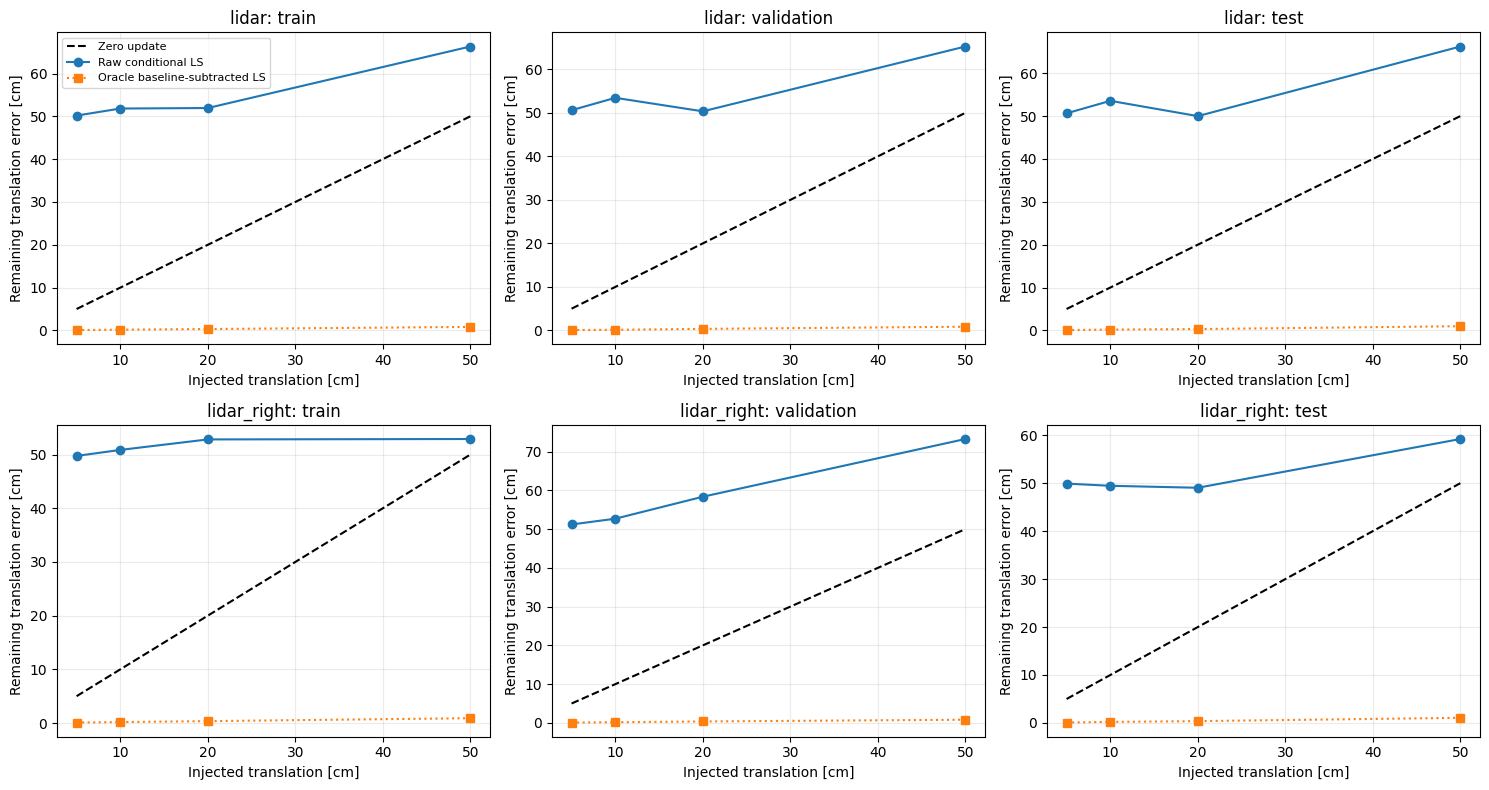

Median false correction [cm] when no perturbation was injected:
split       sensor     
test        lidar          50.0
            lidar_right    50.0
train       lidar          50.0
            lidar_right    50.0
validation  lidar          50.0
            lidar_right    50.0
Fraction of direct-LS cases that improve over zero correction:
split       sensor     
test        lidar           9.2
            lidar_right    11.7
train       lidar           7.8
            lidar_right    12.8
validation  lidar           8.3
            lidar_right     5.8


In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, sensor in enumerate(('lidar', 'lidar_right')):
    for col, split in enumerate(('train', 'validation', 'test')):
        ax = axes[row, col]
        subset = results[(results.sensor == sensor) & (results.split == split)]
        groups = subset.groupby('magnitude_cm')[['initial_cm', 'after_raw_cm', 'after_oracle_cm']].median()
        x = groups.index.to_numpy(dtype=float)
        ax.plot(x, groups['initial_cm'], 'k--', label='Zero update')
        ax.plot(x, groups['after_raw_cm'], 'o-', label='Raw conditional LS')
        ax.plot(x, groups['after_oracle_cm'], 's:', label='Oracle baseline-subtracted LS')
        ax.set_title(f'{sensor}: {split}')
        ax.set_xlabel('Injected translation [cm]')
        ax.set_ylabel('Remaining translation error [cm]')
        ax.grid(alpha=.25)
        if row == 0 and col == 0:
            ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

print('Median false correction [cm] when no perturbation was injected:')
print(results.groupby(['split','sensor'])['nominal_false_update_cm'].median().round(2).to_string())
print('Fraction of direct-LS cases that improve over zero correction:')
print((results.assign(improved=results.after_raw_cm < results.initial_cm).groupby(['split','sensor'])['improved'].mean() * 100).round(1).to_string())

## 12. Feature prototype for a future observability-/residual-informed NN

This section creates example **inference-available** motion features from the *current candidate calibration*: mean residual, RMS, each sensor’s `g = J.T @ r`, each conditional Hessian `H = J.T @ J`, and its eigenvalues. These are physical consistency proxies. They have no target labels mixed into them. Before using them in training, add normalization and test the feature branch with the source `002.10` weights preserved.

In [12]:
def physical_translation_features(pair, delta_left=None, delta_right=None):
    r, JL, JR = translation_pair_data(pair, delta_left=delta_left, delta_right=delta_right)
    features = {}
    for sensor, J in (('lidar', JL), ('lidar_right', JR)):
        flat_J = J.reshape(-1, 3)
        H = flat_J.T @ flat_J
        g = flat_J.T @ r.reshape(-1)
        eig = np.linalg.eigvalsh(H)
        features[sensor] = dict(
            residual_mean_m=r.mean(axis=0),
            residual_rms_m=np.array([residual_rms_m(r)]),
            g=g,
            H=H,
            eigenvalues=eig,
            interval_count=np.array([len(r)], dtype=float),
        )
    return features

features_at_nominal = physical_translation_features(plot_pairs[0])
for key, features in features_at_nominal.items():
    print('\n', key)
    print('  residual mean [m]:', np.round(features['residual_mean_m'], 5))
    print('  signed g:', np.round(features['g'], 6))
    print('  Hessian eigenvalues:', np.round(features['eigenvalues'], 9))

# Contrast two candidate priors without leaking their injected perturbation as a model input.
features_after_10cm = physical_translation_features(plot_pairs[0], delta_left=np.array([0.10, 0., 0.]))
print('\nLeft 10 cm injected: g difference:', np.round(features_after_10cm['lidar']['g'] - features_at_nominal['lidar']['g'], 6))


 lidar
  residual mean [m]: [0.00387 0.00205 0.00088]
  signed g: [-0.000254  0.000682 -0.000643]
  Hessian eigenvalues: [0.00023626 0.00054453 0.00069407]

 lidar_right
  residual mean [m]: [0.00387 0.00205 0.00088]
  signed g: [-3.400e-05 -5.320e-04  1.055e-03]
  Hessian eigenvalues: [0.00026733 0.00041057 0.00050142]

Left 10 cm injected: g difference: [ 2.6e-05 -8.0e-06  1.0e-06]


## 13. Interpretation and go/no-go gates

**Strong positive signal:** raw, conditional LS reduces a majority of 10–20 cm injected translation errors on unseen validation/test windows, with tolerable spurious updates at nominal calibration. Strong oracle-only performance is less impressive: it means the Jacobians detect synthetic perturbations but dataset bias/noise obscures the true calibration.

**Information versus gauge:** if the pairwise 6D information matrix has tiny singular values, left/right disagreement cannot fully distinguish *which sensor* moved or a common frame-origin change. Do not interpret conditional 3D fits as six fully identifiable extrinsic translations.

**Next model choice:** if physical signed gradients are useful, first test the existing tokenizer’s **observability-token pathway**, initialized from `002.10`, against a residual-feature branch. There is no requirement to add a separate MLP before testing the token pathway. If the residual and conditional gradients are weak across most windows, prioritize better measurements/motion excitation or longer observation windows.

**IMU translation:** this notebook does **not** estimate IMU lever-arm translation. It requires acceleration-based body/IMU consistency (including angular acceleration and centripetal terms) or an equivalent factor-graph residual. A pair of LiDAR odometry streams alone does not constrain IMU position.

**Do not use the oracle baseline-subtracted residual as NN input**; at inference time the nominal ground-truth calibration is unknown.